# Whisper checkpoint selection: justifying `whisper-base`

This notebook compares the multilingual Whisper checkpoints (`tiny`, `base`, `small`, `medium`) that were run on the
study set and asks whether `base` is a reasonable primary model for the acoustic-distance vs WER analysis.

1. **Speed vs accuracy:** how much accuracy does each larger model buy, and how much slower is it?
2. **Accent ranking:** do all checkpoints agree on *which* accent groups are transcribed better or worse?
3. **Recording-level agreement:** do the same individual recordings come out worse under every checkpoint?
4. **WER = 0 floor:** larger models transcribe more recordings perfectly. Does that matter for this analysis?
5. **Summary**

Group-level WER is always the **pooled WER**: total errors (S + D + I) in the group divided by total reference words.
Recordings with WER above `WER_CAP` in any model are removed from every model so that comparisons stay paired.

## 0. Configuration

In [4]:
from pathlib import Path

RESULTS_ROOT = Path("../results/asr/")

# One entry per checkpoint. The key must match the checkpoint name after "openai/whisper-".
# Order here = order in every table and figure.
MODEL_DIRS = {
    "tiny":   RESULTS_ROOT / "runs/analysis_tiny_long",
    "base":   RESULTS_ROOT / "runs/analysis_base_long",
    "small":  RESULTS_ROOT / "runs/analysis_small_long",
    "medium": RESULTS_ROOT / "runs/analysis_med_long",
}
CHOSEN_MODEL = "base"

# File-name patterns inside each folder (exactly one file must match each)
SCORED_PATTERN = "scored.csv"
TRANSCRIPTIONS_PATTERN = "*transcription*.csv"

MANIFEST_PATH = RESULTS_ROOT / "runs/analysis_base_long/manifest_snapshot.csv"
ACCENT_COL = "accent_group"
SPEAKER_COL = "speaker_id"         # speaker-level bootstrap for CIs; None = resample individual recordings
SPLIT_GROUPS_BY_DATASET = True     # "yoruba (afrispeech)" and "yoruba (saa)" as separate groups
REFERENCE_ACCENT = "american_english"

WER_CAP = 2.0                      # recordings with WER > this in ANY model are removed from ALL models
MIN_SAMPLES_PER_GROUP = 5          # smaller groups are left out of group-level comparisons
SMALL_GROUP_N = 10                 # groups below this size are drawn dashed in the ranking figure
N_WARMUP_SAMPLES = 5               # first N transcriptions of each run excluded from RTF (GPU warm-up)

# Optional: per-recording acoustic distances, to check whether the distance-WER correlation changes
# with the checkpoint. CSV with a sample_id column plus one column per distance.
DISTANCES_PATH = None              # e.g. Path("../results/distances.csv")
DISTANCE_COLS = None               # e.g. ["mfcc_dist", "pitch_dist"]; None = all numeric columns

FIG_DIR = Path("figures")          # report figures are saved here as PDF and PNG
N_BOOT = 2000
SEED = 42

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 30)
rng = np.random.default_rng(SEED)
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODELS = list(MODEL_DIRS)
OTHERS = [m for m in MODELS if m != CHOSEN_MODEL]

# Fixed colour per model (colour follows the model in every plot)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MODEL_COLORS = {m: PALETTE[i % len(PALETTE)] for i, m in enumerate(MODELS)}
INK, BLUE, ORANGE, GREY = "#33322e", "#2a78d6", "#eb6834", "#b5b4ad"

# Published parameter counts (Radford et al., 2022), in millions
PARAMS_M = {"tiny": 39, "base": 74, "small": 244, "medium": 769, "large": 1550, "large-v2": 1550, "large-v3": 1550}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "pdf.fonttype": 42,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e3e2dc", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#8a8980", "axes.labelcolor": INK, "xtick.color": "#5c5b55",
    "ytick.color": "#5c5b55", "font.size": 10, "legend.frameon": False,
})

# Smaller text for figures sized to one column of the IEEE report
REPORT_STYLE = {"font.size": 8, "axes.labelsize": 8, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
                "legend.fontsize": 7.5}

def save_report_figure(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    print(f"Saved {FIG_DIR / name}.pdf / .png")

## 1. Load and check the results

In [6]:
def find_one(folder, pattern):
    """Return the single file in `folder` matching `pattern`, with a helpful error if there isn't exactly one."""
    folder = Path(folder)
    if not folder.is_dir():
        parent = folder.parent
        siblings = sorted(p.name for p in parent.iterdir() if p.is_dir()) if parent.is_dir() else []
        raise FileNotFoundError(
            f"Folder not found: {folder.resolve()}\n"
            f"(the notebook is running from {Path.cwd()})\n"
            + (f"Folders that do exist in {parent.resolve()}:\n  " + "\n  ".join(siblings) if siblings
               else f"The parent folder {parent.resolve()} does not exist either - check RESULTS_ROOT."))
    matches = sorted(folder.glob(pattern))
    if len(matches) != 1:
        contents = "\n  ".join(sorted(p.name for p in folder.iterdir()))
        raise FileNotFoundError(f"Expected exactly one file matching '{pattern}' in {folder.resolve()}, "
                                f"found {len(matches)}. Folder contains:\n  {contents}")
    return matches[0]

def load_model_results(label, folder):
    scored = pd.read_csv(find_one(folder, SCORED_PATTERN))
    trans = pd.read_csv(find_one(folder, TRANSCRIPTIONS_PATTERN))

    # Guard against pasting the wrong folder into MODEL_DIRS
    names = scored["model_name"].unique()
    if len(names) != 1 or names[0].split("whisper-")[-1] != label:
        raise ValueError(f"MODEL_DIRS['{label}'] points at results for {names}")

    bad = scored[(scored["transcription_status"] != "ok") | (scored["scoring_status"] != "ok")]
    if len(bad):
        print(f"  {label}: dropping {len(bad)} rows that did not transcribe/score cleanly")
    scored = scored.drop(bad.index)

    keep_t = ["sample_id", "transcription_raw", "processed_duration_s", "elapsed_s", "real_time_factor",
              "hardware", "precision", "completed_at_utc"]
    keep_s = ["sample_id", "dataset", "reference_norm", "hypothesis_norm", "wer", "substitutions",
              "deletions", "insertions", "hits", "n_reference_words"]
    df = scored[keep_s].merge(trans[keep_t], on="sample_id", how="left", validate="one_to_one")
    df["errors"] = df["substitutions"] + df["deletions"] + df["insertions"]
    df["model"] = label
    return df

raw = pd.concat([load_model_results(m, f) for m, f in MODEL_DIRS.items()], ignore_index=True)

run_info = (raw.groupby("model", sort=False)
               .agg(n_samples=("sample_id", "size"), hardware=("hardware", "first"),
                    precision=("precision", "first"),
                    run_date=("completed_at_utc", lambda s: str(s.min())[:10])))
display(run_info)
if raw.groupby("model")["hardware"].first().nunique() > 1:
    print("WARNING: models were run on different hardware, so RTF values are not directly comparable.")

,n_samples,hardware,precision,run_date
model,,,,
tiny,546,NVIDIA GeForce RTX 4060 Laptop GPU,torch.float16,2026-10-20
base,580,NVIDIA GeForce RTX 4060 Laptop GPU,torch.float16,2026-10-02
small,580,NVIDIA GeForce RTX 4060 Laptop GPU,torch.float16,2026-10-04
medium,580,NVIDIA GeForce RTX 4060 Laptop GPU,torch.float16,2026-10-04


### 1.1 Restrict every model to the same recordings

Some runs were made on a larger sample set than others. Everything below uses only the recordings that every model
transcribed, so differences between models cannot come from different recordings.

In [7]:
ids_per_model = raw.groupby("model")["sample_id"].apply(set)
common_ids = set.intersection(*ids_per_model)
for m in MODELS:
    extra = len(ids_per_model[m]) - len(common_ids)
    if extra:
        print(f"{m}: {extra} recordings not in every run -> excluded")
data = raw[raw["sample_id"].isin(common_ids)].copy()
print(f"\nRecordings common to all {len(MODELS)} models: {len(common_ids)}")

n_refs = data.groupby("sample_id")["reference_norm"].nunique()
if (n_refs > 1).any():
    print(f"WARNING: {(n_refs > 1).sum()} recordings have different normalised references between runs")
else:
    print("Normalised references are identical across all runs.")

base: 34 recordings not in every run -> excluded
small: 34 recordings not in every run -> excluded
medium: 34 recordings not in every run -> excluded

Recordings common to all 4 models: 546
Normalised references are identical across all runs.


### 1.2 Accent labels

In [8]:
manifest = pd.read_csv(MANIFEST_PATH)
cols = ["sample_id", ACCENT_COL] + ([SPEAKER_COL] if SPEAKER_COL else [])
data = data.merge(manifest[cols].rename(columns={ACCENT_COL: "accent"}), on="sample_id", how="left")
if data["accent"].isna().any():
    missing = data.loc[data["accent"].isna(), "sample_id"].unique()
    raise ValueError(f"{len(missing)} recordings have no accent label in the manifest, e.g. {missing[:5]}")

data["group"] = data["accent"] + " (" + data["dataset"] + ")" if SPLIT_GROUPS_BY_DATASET else data["accent"]

use_speaker = SPEAKER_COL is not None and SPEAKER_COL in data.columns
data["cluster"] = data[SPEAKER_COL] if use_speaker else data["sample_id"]
print("Bootstrap resamples", "speakers" if use_speaker else "individual recordings")

counts = data[data["model"] == CHOSEN_MODEL].groupby(["group", "dataset"]).size().unstack(fill_value=0)
counts["total"] = counts.sum(axis=1)
display(counts.sort_values("total", ascending=False))

Bootstrap resamples speakers


dataset,afrispeech,saa,total
group,,,
american_english (saa),0,309,309
yoruba (afrispeech),102,0,102
kiswahili (afrispeech),45,0,45
hausa (afrispeech),26,0,26
amharic (saa),0,18,18
hindi (saa),0,18,18
hausa (saa),0,9,9
kiswahili (saa),0,7,7
tigrigna (saa),0,7,7


### 1.3 Remove extreme outliers (WER > `WER_CAP`)

A WER above 2 means the model produced more than twice as many errors as there are reference words, almost always
a hallucination loop in long-form decoding, not a measure of accent difficulty. One such recording can dominate a
pooled group WER. A recording is removed from **all** models if it exceeds the cap in **any** model.

In [9]:
wide_wer = data.pivot(index="sample_id", columns="model", values="wer")[MODELS]
flagged = wide_wer[(wide_wer > WER_CAP).any(axis=1)]
print(f"{len(flagged)} recordings exceed WER {WER_CAP} in at least one model:")
info = data[data["model"] == CHOSEN_MODEL].set_index("sample_id")[["group", "n_reference_words"]]
display(info.loc[flagged.index].join(flagged.round(2)))

def pooled_wer(df):
    return df["errors"].sum() / df["n_reference_words"].sum()

before = data.groupby("model", sort=False).apply(pooled_wer, include_groups=False)
data = data[~data["sample_id"].isin(flagged.index)].copy()
after = data.groupby("model", sort=False).apply(pooled_wer, include_groups=False)
display(pd.DataFrame({"pooled WER before cap": before, "pooled WER after cap": after}).T)
print(f"Recordings remaining per model: {data['sample_id'].nunique()}")

6 recordings exceed WER 2.0 in at least one model:


,group,n_reference_words,tiny,base,small,medium
sample_id,,,,,,
afrispeech_03bcfda67aaa67be96d4e44acadf3615,kiswahili (afrispeech),12,3.58,2.50,37.75,37.67
afrispeech_12db0516db3e30de0d08e6eb0cb42370,yoruba (afrispeech),40,0.52,5.55,0.92,0.10
afrispeech_20a455e604ca34b26373f42ea87b791f,yoruba (afrispeech),7,2.14,1.71,1.14,1.14
afrispeech_6a591478925fa58c13108ecadef479be,yoruba (afrispeech),8,55.25,0.62,0.62,0.38
afrispeech_c390d0ff4d09d5e0d6d04dd2a64e5492,yoruba (afrispeech),24,2.75,1.00,0.67,0.46
saa_amharic4,amharic (saa),69,3.17,0.12,0.09,0.07


model,tiny,base,small,medium
pooled WER before cap,0.1249,0.0843,0.0606,0.0504
pooled WER after cap,0.0977,0.0743,0.0427,0.0340


Recordings remaining per model: 540


In [10]:
def bootstrap_pooled_ci(df, n_boot=N_BOOT):
    """95% CI for pooled WER, resampling speakers (or recordings)."""
    g = df.groupby("cluster")[["errors", "n_reference_words"]].sum()
    e, n = g["errors"].to_numpy(float), g["n_reference_words"].to_numpy(float)
    idx = rng.integers(0, len(e), size=(n_boot, len(e)))
    return np.percentile(e[idx].sum(axis=1) / n[idx].sum(axis=1), [2.5, 97.5])

# Group-level comparisons only use groups that are large enough
group_sizes = data[data["model"] == CHOSEN_MODEL]["group"].value_counts()
GROUPS = group_sizes[group_sizes >= MIN_SAMPLES_PER_GROUP].index.tolist()
small_groups = group_sizes[group_sizes < MIN_SAMPLES_PER_GROUP]
if len(small_groups):
    print(f"Left out of group-level comparisons (< {MIN_SAMPLES_PER_GROUP} recordings): {dict(small_groups)}")
gdata = data[data["group"].isin(GROUPS)]
print(f"{len(GROUPS)} accent groups used")

10 accent groups used


**Analysis on data used:**   
 
All four checkpoints were compared on the 546 recordings that every run transcribed (the tiny run was made on the smaller, final sample set). The normalised references were identical across runs, so every model was scored against exactly the same text. Six recordings exceeded WER = 2 in at least one model and were removed from all four. Five of the six are AfriSpeech clips (mostly Yoruba) and one is an SAA Amharic recording; tiny was responsible for five of them, and the worst case (tiny, WER = 55) was a hallucination loop on an 8-word clip. Removing them lowers base's pooled WER from 8.4% to 7.4% and tiny's from 12.5% to 9.8%, which shows how strongly a single runaway transcript can distort a pooled figure. This leaves **540 recordings in 10 accent groups**. Four of those groups (SAA Hausa, Kiswahili, Tigrigna and Yoruba) contain only 5–9 recordings, so their group-level results are much less certain than the rest.

## 2. Speed vs accuracy

RTF = processing time / audio duration (lower is faster). The **median per-recording RTF** is used because it is not
affected by a few slow recordings. The first few transcriptions of each run are excluded as GPU warm-up.

In [11]:
def drop_warmup(df):
    return df.sort_values("completed_at_utc").iloc[N_WARMUP_SAMPLES:]

rows = []
for m in MODELS:
    d = data[data["model"] == m]
    t = drop_warmup(d)
    lo, hi = bootstrap_pooled_ci(d)
    rows.append({
        "model": m,
        "params (M)": PARAMS_M.get(m, np.nan),
        "median RTF": t["real_time_factor"].median(),
        "total run time (min)": d["elapsed_s"].sum() / 60,
        "pooled WER %": pooled_wer(d) * 100,
        "pooled WER 95% CI": f"[{lo*100:.2f}, {hi*100:.2f}]",
        "mean WER %": d["wer"].mean() * 100,
        "median WER %": d["wer"].median() * 100,
    })
cost = pd.DataFrame(rows).set_index("model")
ref = cost.loc[CHOSEN_MODEL]
cost[f"RTF vs {CHOSEN_MODEL} (x)"] = cost["median RTF"] / ref["median RTF"]
cost[f"WER change vs {CHOSEN_MODEL} (pp)"] = cost["pooled WER %"] - ref["pooled WER %"]
display(cost.round(3))

,params (M),median RTF,total run time (min),pooled WER %,pooled WER 95% CI,mean WER %,median WER %,RTF vs base (x),WER change vs base (pp)
model,,,,,,,,,
tiny,39,0.030,5.192,9.774,"[8.68, 11.00]",19.546,5.797,0.781,2.342
base,74,0.038,6.689,7.432,"[6.47, 8.41]",16.213,2.899,1.000,0.000
small,244,0.061,11.012,4.273,"[3.56, 5.01]",9.917,0.725,1.603,-3.159
medium,769,0.100,17.560,3.398,"[2.84, 4.04]",7.914,0.000,2.646,-4.034


Saved figures\model_rtf_vs_wer.pdf / .png


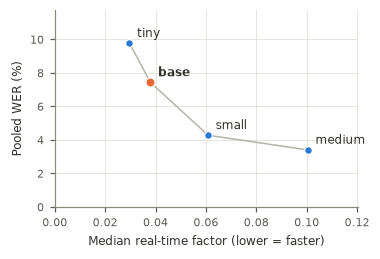

In [12]:
# Figure for the report: speed vs accuracy
with plt.rc_context(REPORT_STYLE):
    fig, ax = plt.subplots(figsize=(3.5, 2.4))
    ax.plot(cost["median RTF"], cost["pooled WER %"], color=GREY, lw=1, zorder=1)
    for m in MODELS:
        x, y = cost.loc[m, "median RTF"], cost.loc[m, "pooled WER %"]
        chosen = m == CHOSEN_MODEL
        ax.plot(x, y, "o", ms=6 if chosen else 5, color=ORANGE if chosen else BLUE, mec="white", mew=0.8, zorder=3)
        ax.annotate(m, (x, y), xytext=(5, 4), textcoords="offset points", color=INK,
                    fontweight="bold" if chosen else "normal")
    ax.set_xlabel("Median real-time factor (lower = faster)")
    ax.set_ylabel("Pooled WER (%)")
    ax.set_ylim(0, cost["pooled WER %"].max() * 1.2)
    ax.set_xlim(0, cost["median RTF"].max() * 1.2)
    plt.tight_layout()
    save_report_figure(fig, "model_rtf_vs_wer")
    plt.show()

### 2.1 Is the timing trustworthy?

RTF also depends on the state of the machine (throttling, power mode, other processes). Every run processes the
recordings in the same order, so this compares each model to `base` *on the same recordings* in each third of the run.
A ratio that stays roughly constant means the run was stable.

In [13]:
rtf_wide = data.pivot(index="sample_id", columns="model", values="real_time_factor")
run_order = drop_warmup(data[data["model"] == CHOSEN_MODEL])["sample_id"].tolist()
thirds = np.array_split(np.array(run_order), 3)
stab = pd.DataFrame({
    part: rtf_wide.loc[ids, MODELS].div(rtf_wide.loc[ids, CHOSEN_MODEL], axis=0).median()
    for part, ids in zip(["first third", "middle third", "last third"], thirds)
}).drop(index=CHOSEN_MODEL)
stab["max / min"] = stab.max(axis=1) / stab.min(axis=1)
print(f"Median per-recording RTF relative to {CHOSEN_MODEL}, in each third of the run:")
display(stab.round(2))
unstable = stab.index[stab["max / min"] > 1.5].tolist()
if unstable:
    print(f"WARNING: the speed of {unstable} relative to {CHOSEN_MODEL} changed by more than 1.5x during the run. "
          "Re-time that model or use the first-third ratio.")

Median per-recording RTF relative to base, in each third of the run:


,first third,middle third,last third,max / min
model,,,,
tiny,0.76,0.77,0.81,1.07
small,1.44,1.68,1.71,1.19
medium,2.33,2.70,2.86,1.23


**Analysis on speed vs accuracy.**

| Step | Pooled WER change | Speed cost |
|---|---|---|
| tiny → base | 9.8% → 7.4% (−2.3 pp) | 1.3× slower |
| base → small | 7.4% → 4.3% (−3.2 pp) | 1.6× slower |
| small → medium | 4.3% → 3.4% (−0.9 pp) | 1.6× slower |

Timing was stable: each model's speed relative to base stayed within about 1.1–1.2× from the start to the end of its run, so these RTFs can be compared directly. Going from tiny to base is cheap; going beyond small gives little extra accuracy for another 1.6× slowdown.

This section on its own does **not** rule out small: base → small is the single biggest accuracy gain, and on this study set the full runs only took 6.7 min (base), 11.0 min (small) and 17.6 min (medium). Speed is therefore a secondary reason for choosing base (it matters more when scaling to more data, or on CPU fallback). The main justification comes from sections 3–5.

## 3. Do the checkpoints agree on which accents are harder?

If every checkpoint ranks the accent groups the same way, the checkpoints differ in **how many** errors they make,
not in **which** accents they struggle with, and the study's conclusions should not depend on the choice.

In [14]:
pooled_table = (gdata.groupby(["group", "model"]).apply(pooled_wer, include_groups=False)
                     .unstack()[MODELS])
ranks = pooled_table.rank(axis=0, method="min").astype(int)
order = ranks[CHOSEN_MODEL].sort_values().index.tolist()      # groups ordered by the chosen model

summary_groups = ((pooled_table * 100).round(1).loc[order]
                  .join(ranks.add_suffix(" rank").loc[order])
                  .assign(n=group_sizes.loc[order]))
print("Pooled WER (%) and rank (1 = lowest WER) of each accent group:")
display(summary_groups)

changed = ranks.loc[ranks.nunique(axis=1) > 1].index.tolist()
print("Groups whose rank changes between checkpoints:")
for g in order:
    if g in changed:
        print(f"  {g}: n = {group_sizes[g]}, ranks {ranks.loc[g, MODELS].tolist()}, "
              f"pooled WER {(pooled_table.loc[g, MODELS] * 100).round(1).tolist()}")

Pooled WER (%) and rank (1 = lowest WER) of each accent group:


model,tiny,base,small,medium,tiny rank,base rank,small rank,medium rank,n
group,,,,,,,,,
american_english (saa),3.1,1.8,0.6,0.5,1,1,1,1,309
hindi (saa),5.2,2.7,1.9,0.9,2,2,2,2,18
hausa (saa),13.4,8.9,4.5,3.4,4,3,4,3,9
tigrigna (saa),14.9,10.4,6.2,5.4,6,4,5,6,7
kiswahili (saa),11.2,11.4,4.3,3.9,3,5,3,5,7
yoruba (saa),14.5,13.3,6.7,3.5,5,6,6,4,5
amharic (saa),19.9,14.2,10.1,8.4,7,7,7,7,17
kiswahili (afrispeech),33.9,29.6,17.2,12.6,8,8,8,8,44
hausa (afrispeech),52.6,45.2,31.2,26.2,9,9,10,10,26


Groups whose rank changes between checkpoints:
  hausa (saa): n = 9, ranks [4, 3, 4, 3], pooled WER [13.4, 8.9, 4.5, 3.4]
  tigrigna (saa): n = 7, ranks [6, 4, 5, 6], pooled WER [14.9, 10.4, 6.2, 5.4]
  kiswahili (saa): n = 7, ranks [3, 5, 3, 5], pooled WER [11.2, 11.4, 4.3, 3.9]
  yoruba (saa): n = 5, ranks [5, 6, 6, 4], pooled WER [14.5, 13.3, 6.7, 3.5]
  hausa (afrispeech): n = 26, ranks [9, 9, 10, 10], pooled WER [52.6, 45.2, 31.2, 26.2]
  yoruba (afrispeech): n = 98, ranks [10, 10, 9, 9], pooled WER [57.1, 46.9, 29.6, 24.2]


Saved figures\model_accent_ranking.pdf / .png


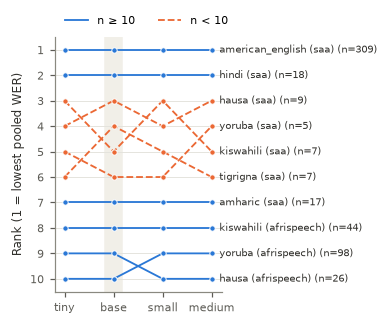

In [15]:
# Figure for the report: rank of each accent group under each checkpoint
with plt.rc_context(REPORT_STYLE):
    fig, ax = plt.subplots(figsize=(3.5, 3.0))
    x = np.arange(len(MODELS))
    ci = MODELS.index(CHOSEN_MODEL)
    ax.axvspan(ci - 0.18, ci + 0.18, color="#f1efe8", zorder=0)
    for g in order:
        small = group_sizes[g] < SMALL_GROUP_N
        y = ranks.loc[g, MODELS].to_numpy()
        ax.plot(x, y, "--" if small else "-", color=ORANGE if small else BLUE, lw=1.2,
                marker="o", ms=3.5, mec="white", mew=0.6, zorder=2 if small else 3)
        ax.annotate(f"{g} (n={group_sizes[g]})", (x[-1], y[-1]), xytext=(5, 0), textcoords="offset points",
                    va="center", fontsize=6.5, color=INK)
    ax.set_xticks(x, MODELS)
    ax.set_xlim(-0.2, len(MODELS) - 0.8)
    ax.set_yticks(range(1, len(order) + 1))
    ax.set_ylim(len(order) + 0.5, 0.5)                    # rank 1 (lowest WER) at the top
    ax.set_ylabel("Rank (1 = lowest pooled WER)")
    ax.grid(axis="x", visible=False)
    ax.plot([], [], "-", color=BLUE, lw=1.2, label=f"n ≥ {SMALL_GROUP_N}")
    ax.plot([], [], "--", color=ORANGE, lw=1.2, label=f"n < {SMALL_GROUP_N}")
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, handlelength=2)
    plt.tight_layout()
    save_report_figure(fig, "model_accent_ranking")
    plt.show()

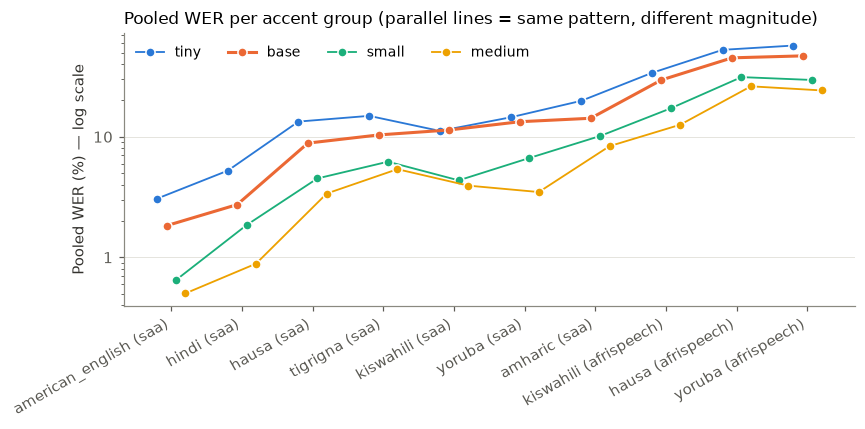

In [16]:
# Pooled WER per group on a log scale: parallel lines = same pattern, different magnitude
fig, ax = plt.subplots(figsize=(8, 4))
xg = np.arange(len(order))
offsets = np.linspace(-0.2, 0.2, len(MODELS))
for off, m in zip(offsets, MODELS):
    y = pooled_table.loc[order, m].clip(lower=1e-3) * 100
    ax.plot(xg + off, y, "-", color=MODEL_COLORS[m], lw=2 if m == CHOSEN_MODEL else 1.2, marker="o", ms=6,
            mec="white", mew=1, label=m, zorder=3 if m == CHOSEN_MODEL else 2)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.grid(axis="x", visible=False)
ax.set_xticks(xg, order, rotation=30, ha="right")
ax.set_ylabel("Pooled WER (%) — log scale")
ax.set_title("Pooled WER per accent group (parallel lines = same pattern, different magnitude)",
             loc="left", fontsize=11)
ax.legend(ncol=len(MODELS), loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

In [17]:
rows = []
for m in OTHERS:
    s = stats.spearmanr(pooled_table[CHOSEN_MODEL], pooled_table[m])
    rows.append({"model": m, "Spearman rho (group pooled WER)": s.statistic, "p": s.pvalue})
print(f"Agreement of the accent-group ranking with {CHOSEN_MODEL} ({len(GROUPS)} groups):")
display(pd.DataFrame(rows).set_index("model").round(4))

Agreement of the accent-group ranking with base (10 groups):


,Spearman rho (group pooled WER),p
model,,
tiny,0.9394,0.0001
small,0.9515,0.0000
medium,0.9394,0.0001


**Analysis on accent ranking:**    

Every checkpoint gives the same overall picture of which accents are harder

* American English (SAA) has the lowest WER and Hindi (SAA) the second lowest in all four models.
* Amharic (SAA) is 7th and Kiswahili (AfriSpeech) 8th in all four models.
* The two highest-WER groups are always AfriSpeech Hausa and Yoruba. They swap places between base and small, but their WERs are close (45.2% vs 46.9% under base, and within about 2 pp under small and medium).
* The only other reordering is among ranks 3–6, which are the four small SAA groups (Hausa, Tigrigna, Kiswahili, Yoruba) with only 5–9 recordings each. Under base their WERs all lie between 8.9% and 13.3%, so a single recording can change their order.

The Spearman correlation between base's group WERs and each other model's is 0.94 (tiny), 0.95 (small) and 0.94 (medium), all p ≤ 0.0001. On the log-scale plot the lines are close to parallel: larger models lower the WER of every group by a similar proportion. In short, **the checkpoints differ in how many errors they make, not in which accents they find hard**, so the group-level conclusions do not depend on choosing base.

## 4. Do the same recordings come out worse under every checkpoint?

The main analysis correlates acoustic distance with WER **per recording**, so the key question is whether the
checkpoints agree on *which individual recordings* are hard. This is the Spearman ρ between `base`'s per-recording WER
and each other model's per-recording WER.

It is computed twice:
* **all recordings:** includes the large differences *between* accent groups and corpora (e.g. AfriSpeech clips are
  much harder than SAA), which pushes ρ up on its own;
* **within each accent group:** the stricter test, among recordings of the same accent, do the models agree on which
  ones are harder?

In [18]:
wide = gdata.pivot(index="sample_id", columns="model", values="wer")[MODELS]
groups_of = gdata[gdata["model"] == CHOSEN_MODEL].set_index("sample_id")["group"]

rows = []
for m in OTHERS:
    row = {"model": m, "all recordings": stats.spearmanr(wide[CHOSEN_MODEL], wide[m]).statistic}
    for g in order:
        ids = groups_of[groups_of == g].index
        row[g] = stats.spearmanr(wide.loc[ids, CHOSEN_MODEL], wide.loc[ids, m]).statistic
    rows.append(row)
sample_rho = pd.DataFrame(rows).set_index("model")
print(f"Spearman rho between per-recording WER of {CHOSEN_MODEL} and each other model:")
display(sample_rho.round(2).T.assign(n=group_sizes.reindex(["all recordings"] + order).fillna(len(wide)).astype(int)))
print("NaN = one model has no variation in that group (e.g. every recording has WER = 0).")

Spearman rho between per-recording WER of base and each other model:


model,tiny,small,medium,n
all recordings,0.88,0.83,0.82,540
american_english (saa),0.69,0.54,0.52,309
hindi (saa),0.66,0.66,0.43,18
hausa (saa),0.81,0.55,0.78,9
tigrigna (saa),0.39,0.85,0.73,7
kiswahili (saa),0.88,0.84,0.69,7
yoruba (saa),0.90,0.67,0.67,5
amharic (saa),0.92,0.94,0.96,17
kiswahili (afrispeech),0.63,0.57,0.55,44
hausa (afrispeech),0.89,0.86,0.69,26


NaN = one model has no variation in that group (e.g. every recording has WER = 0).


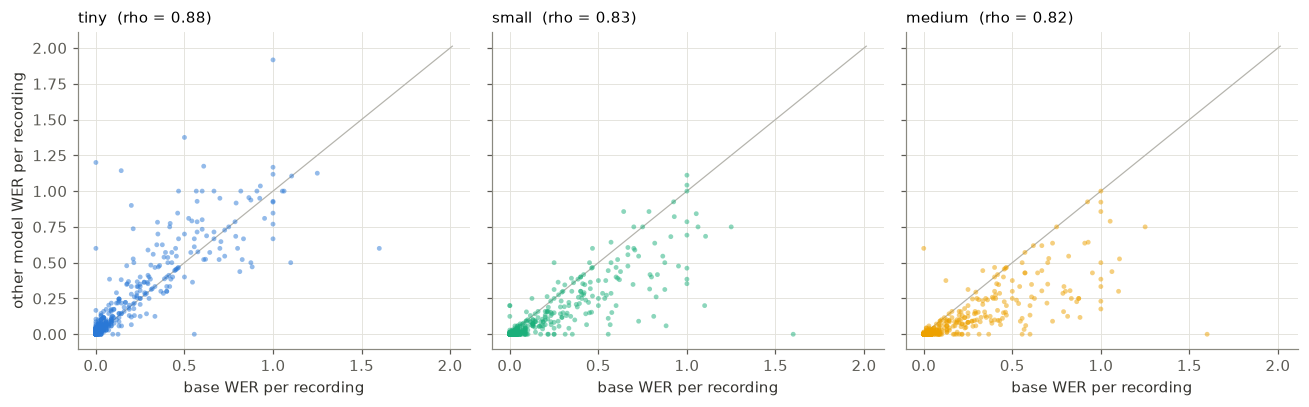

In [19]:
# Per-recording WER of base against each other model (each dot is one recording)
fig, axes = plt.subplots(1, len(OTHERS), figsize=(4 * len(OTHERS), 3.8), sharex=True, sharey=True)
lim = wide.max().max() * 1.05
for ax, m in zip(np.atleast_1d(axes), OTHERS):
    ax.plot([0, lim], [0, lim], color=GREY, lw=0.8, zorder=1)
    ax.scatter(wide[CHOSEN_MODEL], wide[m], s=10, alpha=0.5, color=MODEL_COLORS[m], edgecolor="none", zorder=2)
    ax.set_title(f"{m}  (rho = {sample_rho.loc[m, 'all recordings']:.2f})", loc="left", fontsize=10)
    ax.set_xlabel(f"{CHOSEN_MODEL} WER per recording")
np.atleast_1d(axes)[0].set_ylabel("other model WER per recording")
plt.tight_layout(); plt.show()

**Analysis on recording-level agreement:** 

Across all 540 recordings, base's per-recording WER correlates strongly with the other checkpoints (Spearman ρ = 0.88 with tiny, 0.83 with small, 0.82 with medium): recordings that base finds hard are largely the ones the other models find hard too. Agreement falls slightly as the size gap from base grows.

Part of that overall ρ comes from the large gap *between* groups (AfriSpeech clips are much harder than SAA readings for every model), so the within-group values are the fairer test. In the larger groups they are moderate to strong: 
* Amharic 0.92–0.96, 
* AfriSpeech Hausa 0.69–0.89, 
* AfriSpeech Yoruba 0.66–0.70, 
* AfriSpeech Kiswahili 0.55–0.63 and 
* American English 0.52–0.69. 

The values for the 5–9 recording groups are too unstable to read much into.

Agreement is weakest for American English, and that is mostly a floor effect: small and medium transcribe about three quarters of those recordings perfectly (section 5), so many recordings are tied at zero and the remaining errors are often one-off slips on single words. Overall, a per-recording correlation computed with base should behave similarly to one computed with a larger model, though not identically.

## 5. Recordings with WER = 0; does the floor matter?

The analysis needs **variation in WER** for the acoustic distances to explain. Every recording at WER = 0 is a tie at
the floor: it says nothing about *how much* harder it was than another perfect recording. A larger model that
transcribes most recordings perfectly therefore leaves less signal for a per-recording correlation.

In [21]:
zero_overall = data.groupby("model", sort=False)["wer"].apply(lambda s: (s == 0).mean() * 100)
zero_by_dataset = (data.assign(zero=data["wer"] == 0)
                       .groupby(["model", "dataset"])["zero"].mean().unstack() * 100).loc[MODELS]
zero_by_group = (gdata.assign(zero=gdata["wer"] == 0)
                      .groupby(["model", "group"])["zero"].mean().unstack() * 100).loc[MODELS, order]

print("Share of recordings transcribed perfectly (%):")
display(pd.DataFrame({"all": zero_overall}).join(zero_by_dataset).round(1))
print("Share of recordings with WER = 0 per accent group (%):")
display(zero_by_group.T.round(1).assign(n=group_sizes.loc[order]))

Share of recordings transcribed perfectly (%):


,all,afrispeech,saa
model,,,
tiny,19.1,3.6,26.1
base,29.3,4.8,40.3
small,50.0,11.3,67.5
medium,53.9,14.9,71.5


Share of recordings with WER = 0 per accent group (%):


model,tiny,base,small,medium,n
group,,,,,
american_english (saa),30.7,46.6,76.4,78.6,309
hindi (saa),5.6,22.2,38.9,72.2,18
hausa (saa),0.0,0.0,22.2,33.3,9
tigrigna (saa),0.0,0.0,0.0,0.0,7
kiswahili (saa),0.0,0.0,28.6,28.6,7
yoruba (saa),0.0,0.0,20.0,40.0,5
amharic (saa),5.9,11.8,17.6,17.6,17
kiswahili (afrispeech),6.8,6.8,20.5,31.8,44
hausa (afrispeech),0.0,3.8,7.7,7.7,26


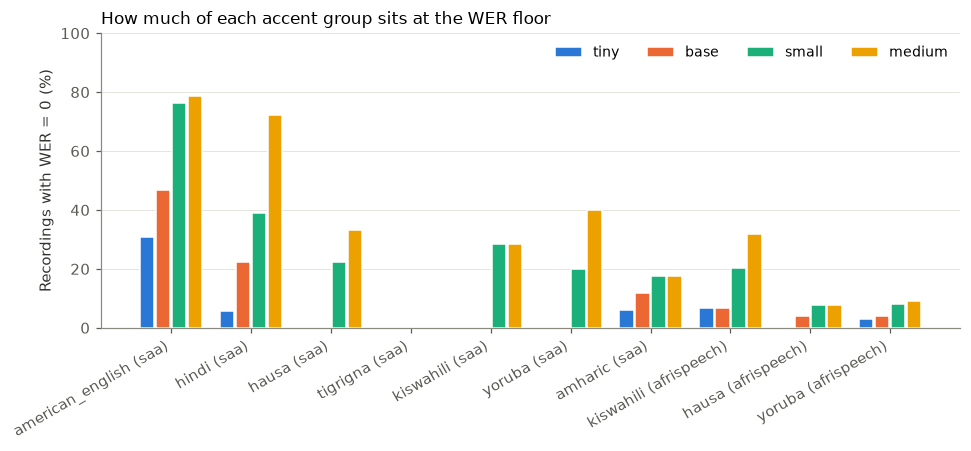

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.2))
xg = np.arange(len(order))
width = 0.8 / len(MODELS)
for i, m in enumerate(MODELS):
    ax.bar(xg + (i - (len(MODELS) - 1) / 2) * width, zero_by_group.loc[m], width=width * 0.9,
           color=MODEL_COLORS[m], label=m, edgecolor="white", linewidth=1)
ax.set_xticks(xg, order, rotation=30, ha="right")
ax.grid(axis="x", visible=False)
ax.set_ylabel("Recordings with WER = 0 (%)")
ax.set_ylim(0, 100)
ax.set_title("How much of each accent group sits at the WER floor", loc="left", fontsize=11)
ax.legend(ncol=len(MODELS), loc="upper right", fontsize=9)
plt.tight_layout(); plt.show()

In [23]:
rows = []
for m in MODELS:
    d = data[data["model"] == m]
    ref = d[d["accent"] == REFERENCE_ACCENT]
    rows.append({
        "model": m,
        "distinct WER values": d["wer"].round(6).nunique(),
        "per-recording WER SD": d["wer"].std(),
        "mean within-group SD": gdata[gdata["model"] == m].groupby("group")["wer"].std().mean(),
        f"{REFERENCE_ACCENT} recordings with WER > 0 (%)": (ref["wer"] > 0).mean() * 100 if len(ref) else np.nan,
    })
print("How much variation in WER is left for the correlation analysis:")
display(pd.DataFrame(rows).set_index("model").round(3))

How much variation in WER is left for the correlation analysis:


,distinct WER values,per-recording WER SD,mean within-group SD,american_english recordings with WER > 0 (%)
model,,,,
tiny,121,0.291,0.152,69.256
base,119,0.262,0.132,53.398
small,103,0.188,0.100,23.625
medium,97,0.158,0.091,21.359


**Analysis on the WER = 0 floor:**

| | tiny | base | small | medium |
|---|---|---|---|---|
| All recordings at WER = 0 | 19% | 29% | 50% | 54% |
| American English at WER = 0 | 31% | 47% | 76% | 79% |
| Mean within-group WER SD | 0.15 | 0.13 | 0.10 | 0.09 |

The floor is almost entirely an SAA effect: AfriSpeech clips are rarely perfect under any model (4–15%), but SAA readings are perfect for 40% of recordings under base and about 70% under small and medium.

This matters because the American English group is the reference that the acoustic distances are measured from. Under small or medium only about 1 in 4–5 American recordings contains any error, so the reference group has almost no WER variation to relate to acoustic distance, and the within-group spread that the per-recording correlation relies on is about 25–30% smaller than with base. Base still transcribes accurately overall (7.4% pooled WER) but keeps errors in about half of the American recordings. Tiny keeps the most variation, but it is the least accurate and produced the most hallucination outliers (five of the six removed in section 1), so its extra variation is partly noise.

More zeros are not a flaw in the larger models; they are simply better. But for a study whose dependent variable is per-recording WER, the most accurate checkpoint is not automatically the most informative one.

One caveat to state in the report: some of the extra errors base makes may come from general model weakness (for example clinical vocabulary in AfriSpeech) rather than accent. Section 3 is the check on this: the accent pattern is the same for every checkpoint, so these extra errors do not reshape the accent comparison.

## 6. Summary

In [24]:
summary_rows = []
for m in MODELS:
    d = data[data["model"] == m]
    row = {
        "model": m,
        "params (M)": PARAMS_M.get(m, np.nan),
        "median RTF": cost.loc[m, "median RTF"],
        "pooled WER %": pooled_wer(d) * 100,
        "% WER = 0": (d["wer"] == 0).mean() * 100,
        f"{REFERENCE_ACCENT} % WER = 0": (d.loc[d["accent"] == REFERENCE_ACCENT, "wer"] == 0).mean() * 100,
    }
    if m != CHOSEN_MODEL:
        row[f"group rho vs {CHOSEN_MODEL}"] = stats.spearmanr(pooled_table[CHOSEN_MODEL], pooled_table[m]).statistic
        row[f"recording rho vs {CHOSEN_MODEL}"] = sample_rho.loc[m, "all recordings"]
    summary_rows.append(row)
display(pd.DataFrame(summary_rows).set_index("model").round(3))
print(f"Recordings analysed: {data['sample_id'].nunique()} (after removing {len(flagged)} with WER > {WER_CAP})")
print(f"Accent groups compared: {len(GROUPS)}")

,params (M),median RTF,pooled WER %,% WER = 0,american_english % WER = 0,group rho vs base,recording rho vs base
model,,,,,,,
tiny,39,0.030,9.774,19.074,30.744,0.939,0.877
base,74,0.038,7.432,29.259,46.602,NaN,NaN
small,244,0.061,4.273,50.000,76.375,0.952,0.830
medium,769,0.100,3.398,53.889,78.641,0.939,0.817


Recordings analysed: 540 (after removing 6 with WER > 2.0)
Accent groups compared: 10


**Conclusion.** Whisper-base was chosen as the primary model because:

1. **The accent pattern does not depend on the checkpoint.** All four models rank the accent groups in nearly the same order (Spearman ρ with base 0.94–0.95). The only changes are among the four SAA groups with 5–9 recordings, and between the two highest-WER AfriSpeech groups, whose WERs are within about 2 pp of each other.
2. **Individual recordings behave similarly across checkpoints.** Base's per-recording WER correlates 0.82–0.88 with the other models, so a per-recording analysis with base should resemble one with a larger model.
3. **Larger models leave too little WER variation.** Small and medium transcribe 76–79% of the American English reference recordings perfectly, against 47% for base, leaving little per-recording variation for the acoustic-distance correlation.
4. **Accuracy is reasonable and cost is low.** Base cuts tiny's pooled WER from 9.8% to 7.4% for a 1.3× slowdown, while small and medium are 1.6× and 2.6× slower than base.

The larger checkpoints are more accurate in absolute terms (4.3% and 3.4% pooled WER). Since they change the size of the errors but not which accents are harder, they are reported as a robustness check rather than used as the primary model.